# Clean & Analyze Social Media

## Introduction

Social media has become a ubiquitous part of modern life, with platforms such as Instagram, Twitter, and Facebook serving as essential communication channels. Social media data sets are vast and complex, making analysis a challenging task for businesses and researchers alike. In this project, we explore a simulated social media, for example Tweets, Posts data set to understand trends in likes across different categories.

## Prerequisites

To follow along with this project, you should have a basic understanding of Python programming and data analysis concepts. In addition, you may want to use the following packages in your Python environment:

- pandas
- numpy
- Matplotlib
- Seaborn
- notebook

These packages should already be installed in Coursera's Jupyter Notebook environment, however if you'd like to install additional packages that are not included in this environment or are working off platform you can install additional packages using `!pip install packagename` within a notebook cell such as:

- `pip install -r requirements.txt`

## Project Scope

The objective of this project is to analyze tweets (or other social media data) and gain insights into user engagement. We will explore the data set using visualization techniques to understand the distribution of likes across different categories. Finally, we will analyze the data to draw conclusions about the most popular categories and the overall engagement on the platform.

## Step 1: Importing Required Libraries

As the name suggests, the first step is to import all the necessary libraries that will be used in the project. In this case, we need pandas, numpy, matplotlib, seaborn, and random libraries.

Pandas is a library used for data manipulation and analysis. Numpy is a library used for numerical computations. Matplotlib is a library used for data visualization. Seaborn is a library used for statistical data visualization. Random is a library used to generate random numbers.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv('./data/sentimentdataset.csv')

In [14]:
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [15]:
df.tail()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
727,728,732,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20.0,39.0,UK,2017,8,18,18
728,729,733,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25.0,48.0,USA,2018,6,22,14
729,730,734,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22.0,42.0,Canada,2019,4,5,17
730,731,735,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21.0,43.0,UK,2020,2,29,20
731,732,736,Organizing a virtual talent show during challe...,Happy,2020-11-15 15:15:00,VirtualTalentShowSuccessHighSchool,Instagram,#VirtualEntertainment #HighSchoolPositivity,24.0,47.0,USA,2020,11,15,15


In [17]:
df.shape

(732, 15)

In [19]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User',
       'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month',
       'Day', 'Hour'],
      dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


## Analyzing Individual Feature Patterns using Visualization

How to choose the right visualization method?
When visualizing individual variables, it is important to first understand what type of variable you are dealing with. This will help us find the right visualization method for that variable.

In [10]:
print(df.dtypes)

Unnamed: 0.1      int64
Unnamed: 0        int64
Text             object
Sentiment        object
Timestamp        object
User             object
Platform         object
Hashtags         object
Retweets        float64
Likes           float64
Country          object
Year              int64
Month             int64
Day               int64
Hour              int64
dtype: object


In [22]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month
df['Year'] = df['Timestamp'].dt.year

In [23]:
df['Text'] = df['Text'].str.strip()
df['Sentiment'] = df['Sentiment'].str.strip()
df['User'] = df['User'].str.strip()
df['Platform'] = df['Platform'].str.strip()
df['Hashtags'] = df['Hashtags'].str.strip()
df['Country'] = df['Country'].str.strip()

In [24]:
df["Retweets"] = df["Retweets"].astype(int)
df["Likes"] = df["Likes"].astype(int)

In [25]:
df.drop(columns = ["Unnamed: 0.1","Unnamed: 0"],axis = 1, inplace = True)

In [27]:
df

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,Enjoying a beautiful day at the park!,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,Just finished an amazing workout! 💪,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,Excited about the upcoming weekend getaway!,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,Trying out a new recipe for dinner tonight.,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...
727,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20,39,UK,2017,8,18,18
728,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25,48,USA,2018,6,22,14
729,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22,42,Canada,2019,4,5,17
730,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21,43,UK,2020,2,29,20


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Text       732 non-null    object        
 1   Sentiment  732 non-null    object        
 2   Timestamp  732 non-null    datetime64[ns]
 3   User       732 non-null    object        
 4   Platform   732 non-null    object        
 5   Hashtags   732 non-null    object        
 6   Retweets   732 non-null    int64         
 7   Likes      732 non-null    int64         
 8   Country    732 non-null    object        
 9   Year       732 non-null    int32         
 10  Month      732 non-null    int32         
 11  Day        732 non-null    int32         
 12  Hour       732 non-null    int64         
dtypes: datetime64[ns](1), int32(3), int64(3), object(6)
memory usage: 65.9+ KB


In [29]:
df.isnull().sum().sum()

np.int64(0)

In [30]:
df.duplicated().value_counts()

False    710
True      22
Name: count, dtype: int64

In [31]:
df.describe()

,Timestamp,Retweets,Likes,Year,Month,Day,Hour
count,732,732.000000,732.000000,732.000000,732.000000,732.000000,732.000000
mean,2020-12-08 21:37:38.196721408,21.508197,42.901639,2020.471311,6.122951,15.497268,15.521858
min,2010-05-15 15:30:00,5.000000,10.000000,2010.000000,1.000000,1.000000,0.000000
25%,2019-03-08 17:27:30,17.750000,34.750000,2019.000000,3.000000,9.000000,13.000000
50%,2021-09-20 14:30:00,22.000000,43.000000,2021.000000,6.000000,15.000000,16.000000
75%,2023-02-26 11:48:45,25.000000,50.000000,2023.000000,9.000000,22.000000,19.000000
max,2023-10-22 20:45:00,40.000000,80.000000,2023.000000,12.000000,31.000000,23.000000
std,NaN,7.061286,14.089848,2.802285,3.411763,8.474553,4.113414


In [32]:
k = df.describe(include="object")

In [33]:
k

,Text,Sentiment,User,Platform,Hashtags,Country
count,732,732,732,732,732,732
unique,706,191,670,3,692,33
top,"A compassionate rain, tears of empathy falling...",Positive,CarnivalDreamer,Instagram,#Compassionate #TearsOfEmpathy,USA
freq,3,45,3,258,3,188


In [34]:
for i in k.columns:
    print(i)
    print(df[i].unique())
    print("*"*50)

Text
['Enjoying a beautiful day at the park!'
 'Traffic was terrible this morning.'
 'Just finished an amazing workout! 💪'
 'Excited about the upcoming weekend getaway!'
 'Trying out a new recipe for dinner tonight.'
 'Feeling grateful for the little things in life.'
 'Rainy days call for cozy blankets and hot cocoa.'
 'The new movie release is a must-watch!'
 'Political discussions heating up on the timeline.'
 'Missing summer vibes and beach days.'
 'Just published a new blog post. Check it out!'
 'Feeling a bit under the weather today.'
 "Exploring the city's hidden gems." 'New year, new fitness goals! 💪'
 'Technology is changing the way we live.'
 'Reflecting on the past and looking ahead.'
 'Just adopted a cute furry friend! 🐾'
 'Late-night gaming session with friends.'
 'Attending a virtual conference on AI.'
 'Winter blues got me feeling low.'
 'Sipping coffee and enjoying a good book.'
 'Exploring the world of virtual reality.'
 'Productive day ticking off my to-do list.'
 'Jus

In [35]:
df

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,Enjoying a beautiful day at the park!,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,Just finished an amazing workout! 💪,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,Excited about the upcoming weekend getaway!,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,Trying out a new recipe for dinner tonight.,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...
727,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20,39,UK,2017,8,18,18
728,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25,48,USA,2018,6,22,14
729,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22,42,Canada,2019,4,5,17
730,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21,43,UK,2020,2,29,20


In [36]:
df.columns

Index(['Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags',
       'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour'],
      dtype='object')

In [37]:
sten = df["Sentiment"].value_counts().head(10).reset_index()
sen = pd.DataFrame(sten)
sen

,Sentiment,count
0,Positive,45
1,Joy,44
2,Excitement,37
3,Contentment,19
4,Neutral,18
5,Gratitude,18
6,Curiosity,16
7,Serenity,15
8,Happy,14
9,Despair,11


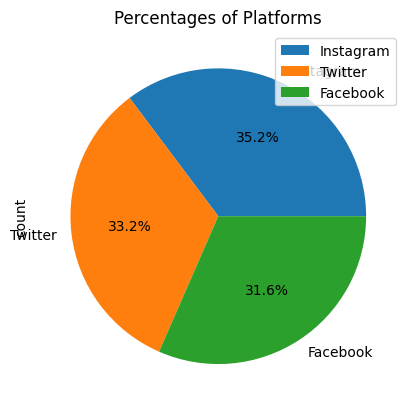

In [38]:
df['Platform'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Percentages of Platforms')
plt.legend()
plt.show()

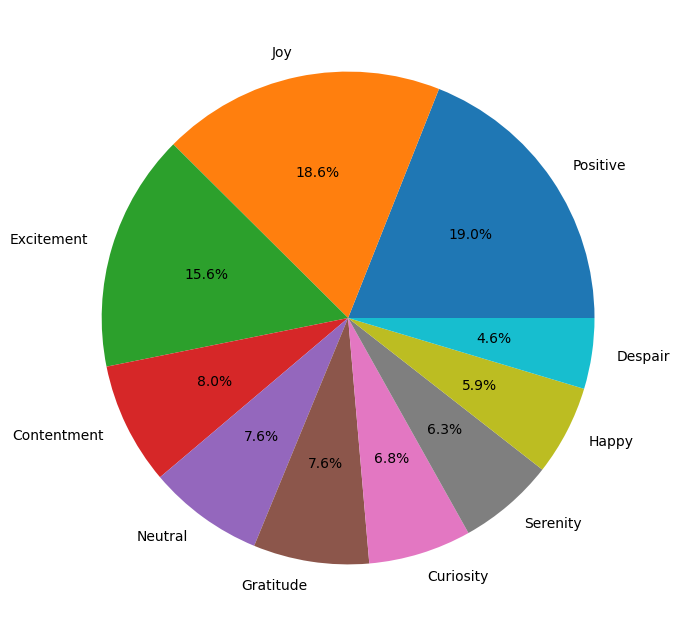

In [39]:
plt.figure(figsize=(10,8))
s = plt.pie(sen["count"], labels = sen["Sentiment"],autopct='%1.1f%%')
plt.show()

In [40]:
k = df["Hashtags"].value_counts().head(10).reset_index()
Hash = pd.DataFrame(k)
Hash

,Hashtags,count
0,#Compassionate #TearsOfEmpathy,3
1,#Proud #ScalingPeaks,3
2,#Hopeful #SeedsOfOptimism,3
3,#Playful #CarnivalEscapade,3
4,#Love #SpreadLove,2
5,#Inspired #CloudsOfCreativity,2
6,#Frustration #EmotionalOutburst,2
7,#Contentment #TranquilWaters,2
8,#Confusion #ThoughtLabyrinth,2
9,#Acceptance #LifeJourney,2


C:\Users\ROHAN\AppData\Local\Temp\ipykernel_22352\3364657868.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  k = sns.barplot(y = "Hashtags", x = "count", data = Hash, palette = "gist_ncar")


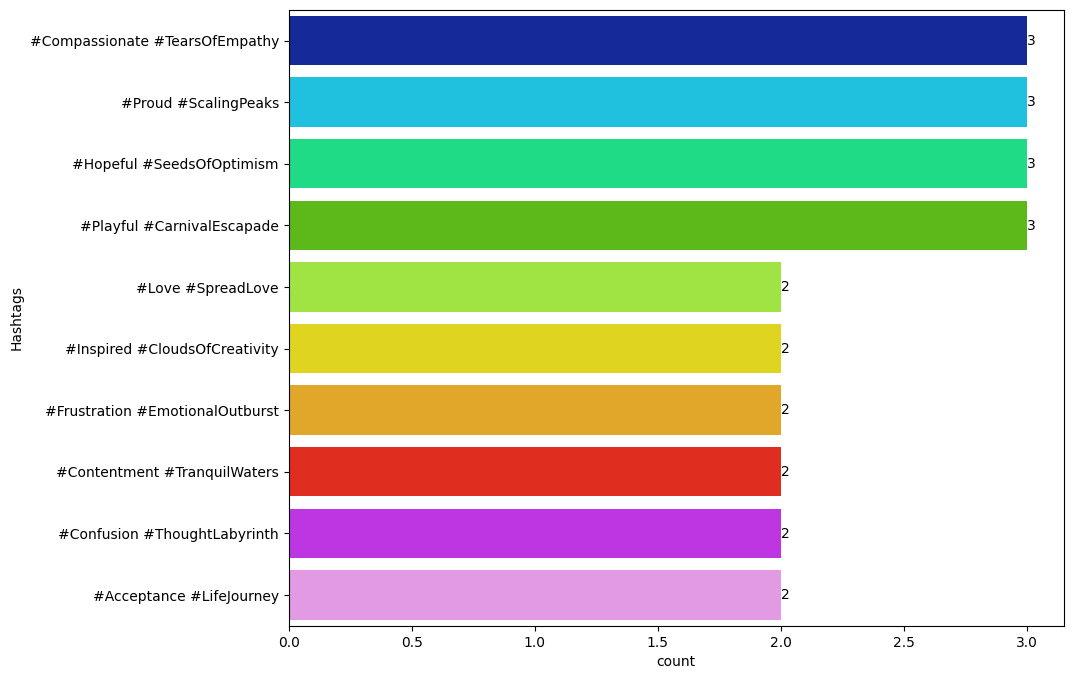

In [41]:
plt.figure(figsize = (10,8))
k = sns.barplot(y = "Hashtags", x = "count", data = Hash, palette = "gist_ncar")
for bars in k.containers:
    k.bar_label(bars)
plt.show()

In [42]:
k = df.groupby("Hashtags")["Retweets"].max().nlargest(10).sort_values(ascending = False).reset_index()
b = pd.DataFrame(k)
b

,Hashtags,Retweets
0,#Anticipation #AdventureAwaits,40
1,#Despair #AbyssOfHeartache,40
2,#Disappointment #SoccerDefeats,40
3,#Elation #RareBookDiscovery,40
4,#Emotion #AdeleConcert,40
5,#Enthusiasm #JustinBieber,40
6,#Excitement #MoviePremiereThrills,40
7,#Joy #EndlessSmiles,40
8,#Joy #SimpleMoments,40
9,#Joy #WorldCupTriumph,40


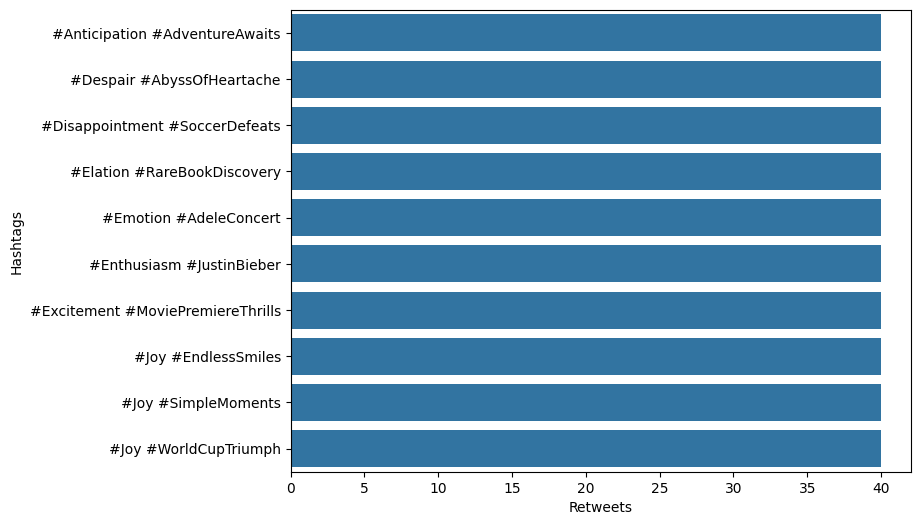

In [43]:
plt.figure(figsize = (8,6))
sns.barplot(x = "Retweets", y = "Hashtags", data = b)
plt.show()


In [44]:
k = df.groupby("Hashtags")["Likes"].max().nlargest(10).reset_index()
b = pd.DataFrame(k)
b

,Hashtags,Likes
0,#Anticipation #AdventureAwaits,80
1,#Despair #AbyssOfHeartache,80
2,#Disappointment #SoccerDefeats,80
3,#Elation #RareBookDiscovery,80
4,#Emotion #AdeleConcert,80
5,#Enthusiasm #JustinBieber,80
6,#Excitement #MoviePremiereThrills,80
7,#Joy #EndlessSmiles,80
8,#Joy #SimpleMoments,80
9,#Joy #WorldCupTriumph,80


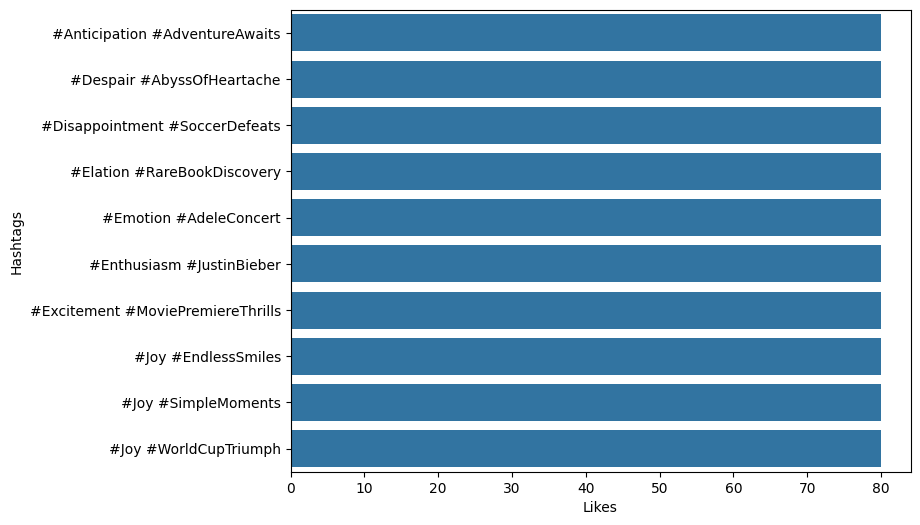

In [45]:
plt.figure(figsize = (8,6))
sns.barplot(x = "Likes", y = "Hashtags", data = b)
plt.show()

In [46]:
k = df.groupby('Year')['Likes'].sum().reset_index()
ly = pd.DataFrame(k)
ly

,Year,Likes
0,2010,160
1,2011,185
2,2012,160
3,2013,175
4,2014,160
5,2015,859
6,2016,1661
7,2017,1785
8,2018,2505
9,2019,3224


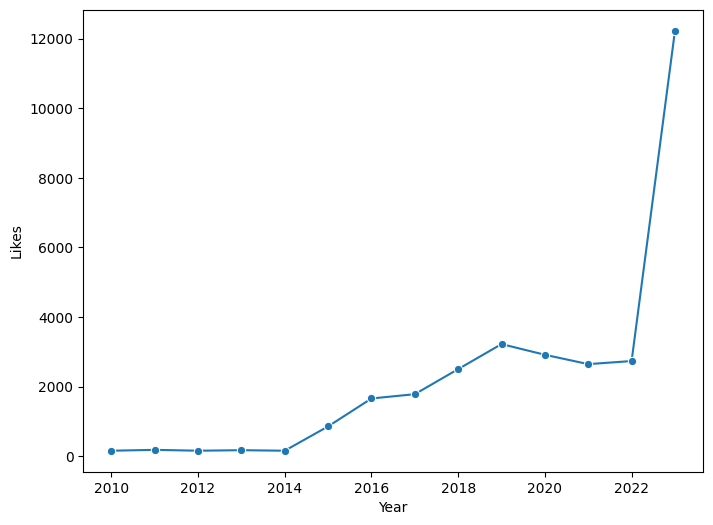

In [47]:
plt.figure(figsize = (8,6))
sns.lineplot(x = "Year", y = "Likes", data = ly, marker = "o")
plt.show()

In [48]:
k = df.groupby("Sentiment")["Likes"].sum().nlargest(10).reset_index()
k = pd.DataFrame(k)
k

,Sentiment,Likes
0,Joy,2168
1,Excitement,1860
2,Positive,1700
3,Contentment,976
4,Gratitude,885
5,Neutral,729
6,Curiosity,688
7,Serenity,636
8,Happy,632
9,Awe,400


C:\Users\ROHAN\AppData\Local\Temp\ipykernel_22352\53349175.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = "Sentiment",y = "Likes",data= k ,palette="gist_ncar",)


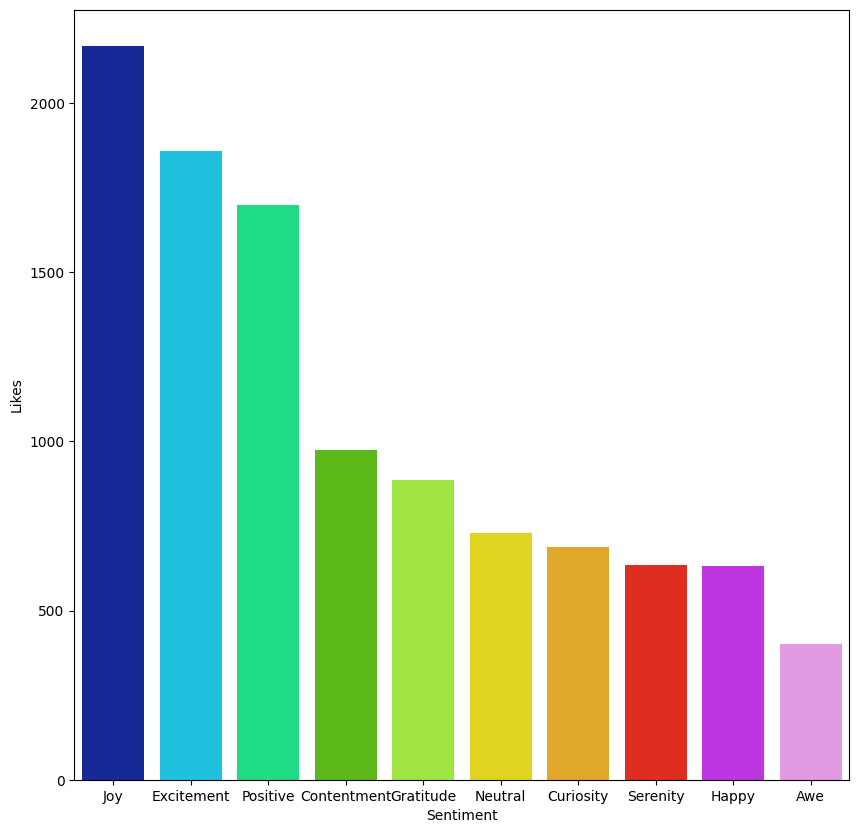

In [49]:
plt.figure(figsize=(10,10))
sns.barplot(x = "Sentiment",y = "Likes",data= k ,palette="gist_ncar",)
plt.show()

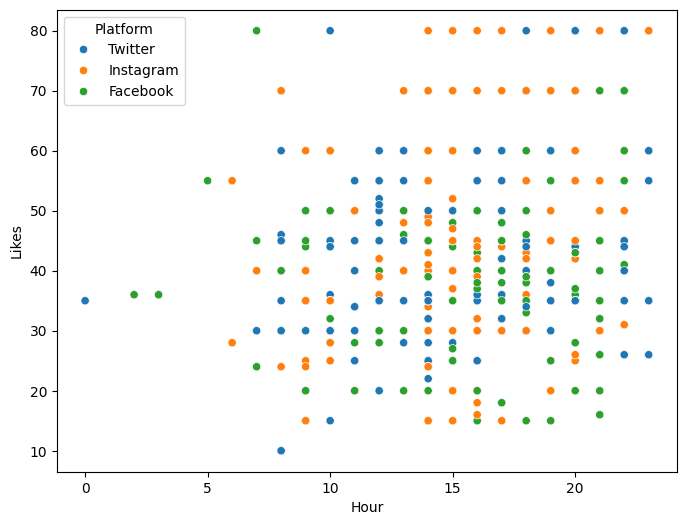

In [50]:
plt.figure(figsize=(8,6))
sns.scatterplot(data = df, x = 'Hour', y = 'Likes',hue = "Platform")
plt.show()

In [51]:
k = df["Country"].value_counts().nlargest(10).reset_index()
b = pd.DataFrame(k)
b

,Country,count
0,USA,188
1,UK,143
2,Canada,135
3,Australia,75
4,India,70
5,Brazil,17
6,France,16
7,Japan,15
8,Germany,14
9,Italy,11


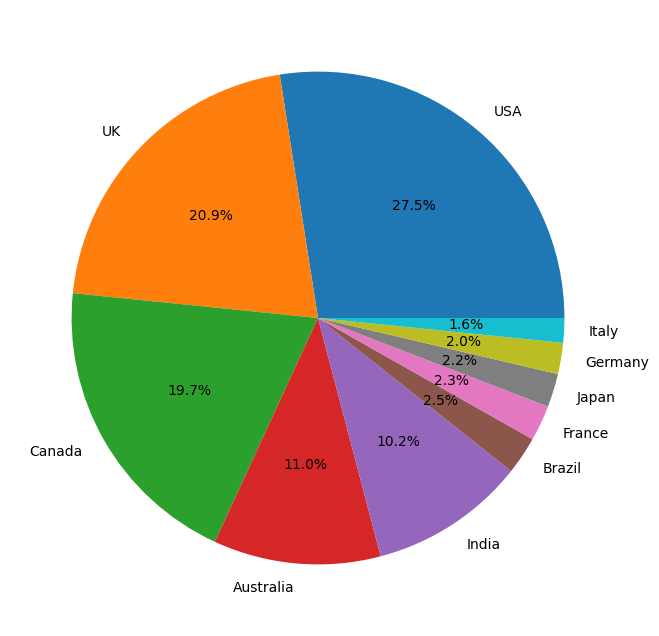

In [52]:
plt.figure(figsize=(12,8))
s = plt.pie(b["count"], labels = b["Country"],autopct='%1.1f%%')
plt.show()

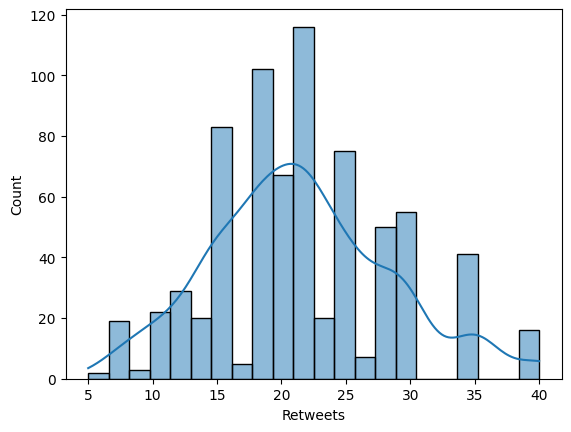

In [53]:
sns.histplot(df.Retweets,kde = True)
plt.show()

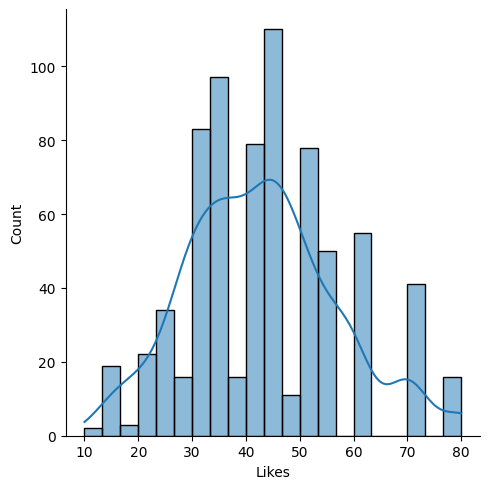

In [54]:
sns.displot(df.Likes,kde = True)
plt.show()

In [55]:
k = df.groupby("Text")["Retweets"].sum().nlargest(10)
tophash = pd.DataFrame(k)
tophash

,Retweets
Text,
"A playful escapade in the carnival of life, carousel laughter and cotton candy dreams swirling in the joyous atmosphere.",72
"Proudly scaling the peaks of achievement, a mountaineer conquering challenges and planting the flag of success.",69
"A compassionate rain, tears of empathy falling gently, nurturing the seeds of kindness in the garden of human connections.",63
Savoring the warmth of a cup of cocoa on a chilly winter evening.,60
Whispers of inspiration from the rustling leaves in a serene forest.,56
"Playfully juggling responsibilities, a circus performer balancing the acts of work and joy, tossing laughter into the air.",50
"Confident strides in the dance of life, a ballroom where self-assuredness leads, twirling through challenges with grace.",46
"A free spirit soaring on the wings of dreams, leaving trails of independence in the azure sky of boundless possibilities.",44
Heartfelt gratitude for the laughter shared during a family reunion.,44
